In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_key_rate = pd.read_parquet("data/processed/key_rate.parquet")
df_ruonia = pd.read_parquet("data/processed/ruonia.parquet").drop(columns="volume_bln_rub")
df_zcyc = pd.read_parquet("data/processed/zcyc.parquet")

In [3]:
df_key_rate.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3231 entries, 0 to 3230
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          3231 non-null   datetime64[ns]
 1   key_rate_pct  3231 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 50.6 KB


In [4]:
df_ruonia.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3165 entries, 0 to 3164
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        3165 non-null   datetime64[ns]
 1   ruonia_pct  3165 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 49.6 KB


In [5]:
df_zcyc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38892 entries, 0 to 38891
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         38892 non-null  datetime64[ns]
 1   tenor_years  38892 non-null  float64       
 2   yield_pct    38892 non-null  float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 911.7 KB


In [6]:
df_zcyc_wide = df_zcyc.pivot(
    index='date',
    columns='tenor_years',
    values='yield_pct'
).reset_index()

df_zcyc_wide.head()

tenor_years,date,0.25,0.5,0.75,1.0,2.0,3.0,5.0,7.0,10.0,15.0,20.0,30.0
0,2014-01-06,5.92,6.02,6.10,6.19,6.50,6.77,7.21,7.55,7.91,8.29,8.50,8.72
1,2014-01-08,5.92,6.01,6.10,6.19,6.49,6.75,7.19,7.54,7.94,8.34,8.54,8.74
2,2014-01-09,5.78,5.87,5.97,6.07,6.45,6.79,7.29,7.65,8.02,8.36,8.54,8.74
3,2014-01-10,5.70,5.81,5.92,6.02,6.43,6.78,7.31,7.67,8.03,8.36,8.54,8.74
4,2014-01-13,5.81,5.90,5.99,6.07,6.41,6.76,7.29,7.66,8.03,8.38,8.57,8.77


In [7]:
df_zcyc_wide.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3241 entries, 0 to 3240
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    3241 non-null   datetime64[ns]
 1   0.25    3241 non-null   float64       
 2   0.5     3241 non-null   float64       
 3   0.75    3241 non-null   float64       
 4   1.0     3241 non-null   float64       
 5   2.0     3241 non-null   float64       
 6   3.0     3241 non-null   float64       
 7   5.0     3241 non-null   float64       
 8   7.0     3241 non-null   float64       
 9   10.0    3241 non-null   float64       
 10  15.0    3241 non-null   float64       
 11  20.0    3241 non-null   float64       
 12  30.0    3241 non-null   float64       
dtypes: datetime64[ns](1), float64(12)
memory usage: 329.3 KB


In [8]:
df = pd.merge(
    df_key_rate,
    df_ruonia,
    on="date",
    how="inner"
)

df = pd.merge(
    df,
    df_zcyc_wide,
    on="date",
    how="inner"
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3151 entries, 0 to 3150
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          3151 non-null   datetime64[ns]
 1   key_rate_pct  3151 non-null   float64       
 2   ruonia_pct    3151 non-null   float64       
 3   0.25          3151 non-null   float64       
 4   0.5           3151 non-null   float64       
 5   0.75          3151 non-null   float64       
 6   1.0           3151 non-null   float64       
 7   2.0           3151 non-null   float64       
 8   3.0           3151 non-null   float64       
 9   5.0           3151 non-null   float64       
 10  7.0           3151 non-null   float64       
 11  10.0          3151 non-null   float64       
 12  15.0          3151 non-null   float64       
 13  20.0          3151 non-null   float64       
 14  30.0          3151 non-null   float64       
dtypes: datetime64[ns](1), float64(14)
memo

In [9]:
max_rows = max([
        df_key_rate.shape[0],
        df_ruonia.shape[0],
        df_zcyc_wide.shape[0]
    ])

print(
    f"Потеряно записей: {max_rows - df.shape[0]} ({(max_rows - df.shape[0]) / max_rows * 100 :.2f}%)"
)

print(
    f"Количество дубликатов по дате: {int(df.duplicated(subset='date').sum())}"
)

print(
    f"Количество пустых значений: \n{df.isna().sum()}"
)

Потеряно записей: 90 (2.78%)
Количество дубликатов по дате: 0
Количество пустых значений: 
date            0
key_rate_pct    0
ruonia_pct      0
0.25            0
0.5             0
0.75            0
1.0             0
2.0             0
3.0             0
5.0             0
7.0             0
10.0            0
15.0            0
20.0            0
30.0            0
dtype: int64


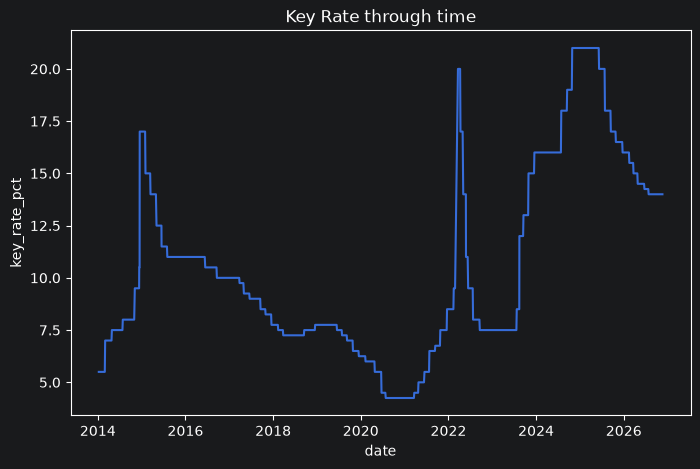

In [10]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    df,
    x="date",
    y="key_rate_pct"
)

plt.title("Key Rate through time")
plt.show()

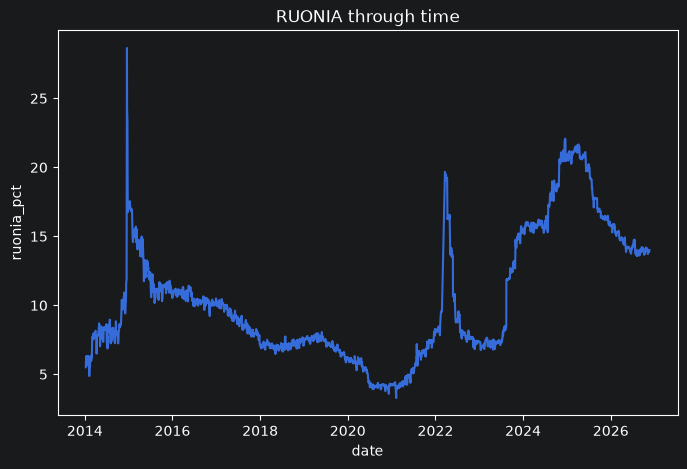

In [11]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    df,
    x="date",
    y="ruonia_pct"
)

plt.title("RUONIA through time")
plt.show()

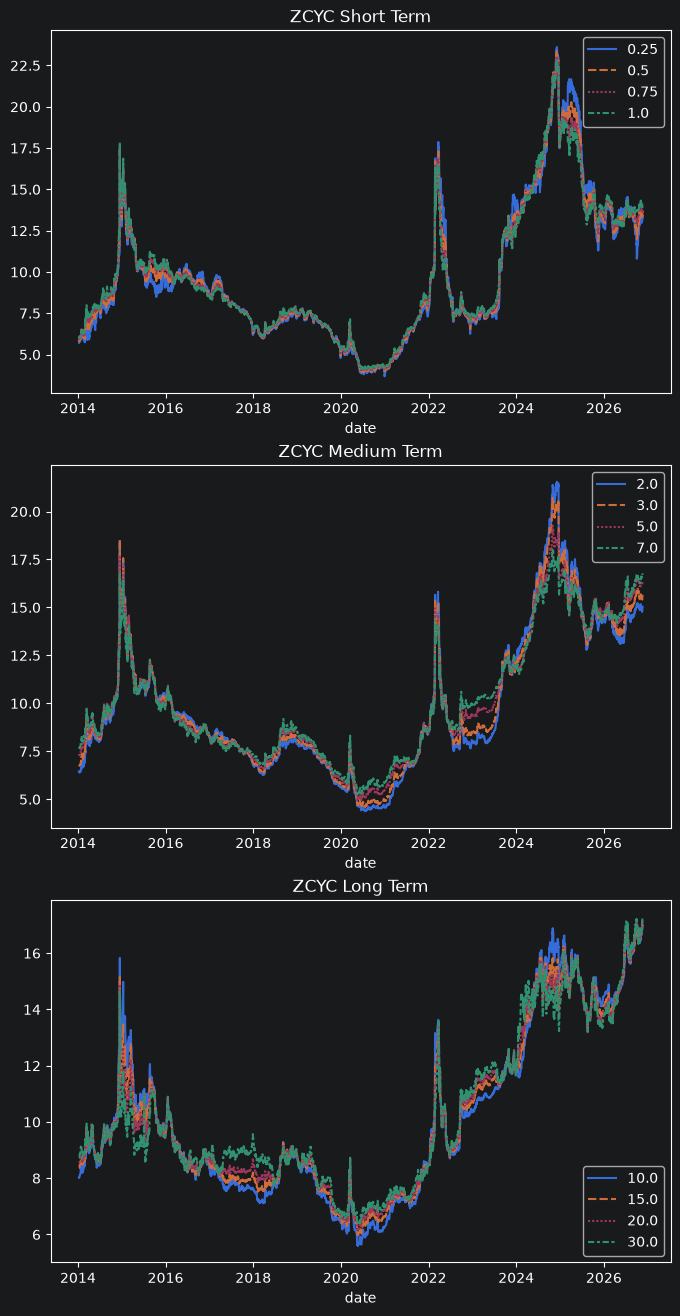

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(8, 16))

(ax1, ax2, ax3) = axes.flatten()

sns.lineplot(
    data=df.set_index("date")[[0.25, 0.5, 0.75, 1.0]],
    ax=ax1
)
ax1.set_title("ZCYC Short Term")


sns.lineplot(
    data=df.set_index("date")[[2, 3, 5, 7]],
    ax=ax2
)
ax2.set_title("ZCYC Medium Term")


sns.lineplot(
    data=df.set_index("date")[[10, 15, 20, 30]],
    ax=ax3
)
ax3.set_title("ZCYC Long Term")


plt.show()

## Main periods:
   * 2014 - 2015
   * 2020 - 2022
   * 2023 - 2026

## 2014 - 2015 period

Выброс в конце 2014 года не удаляем - он реален, ЦБ тогда резко повысил ставку с 10% до 17%

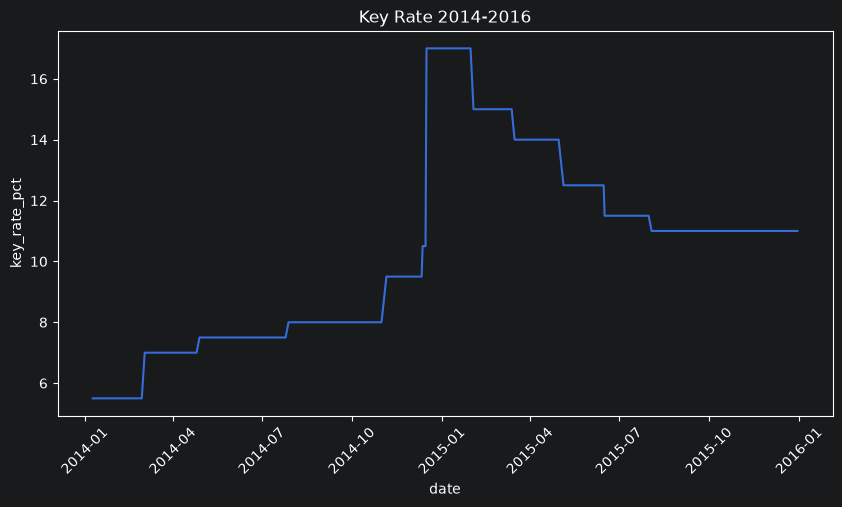

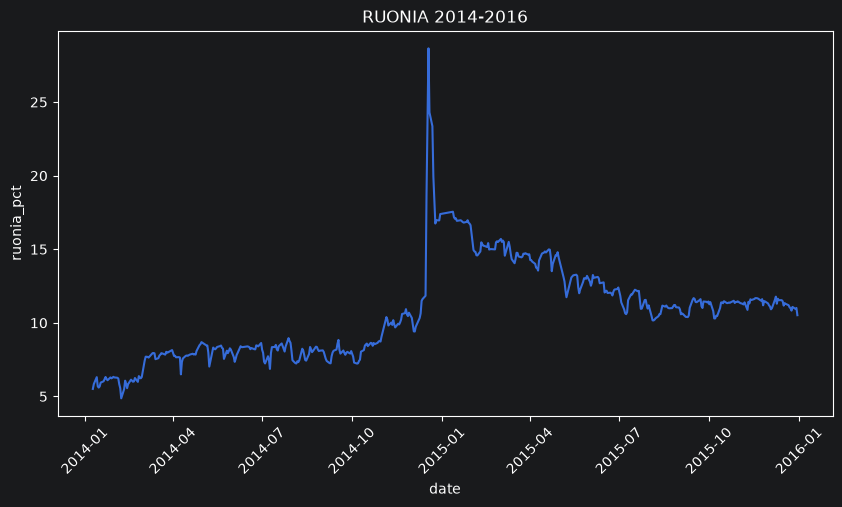

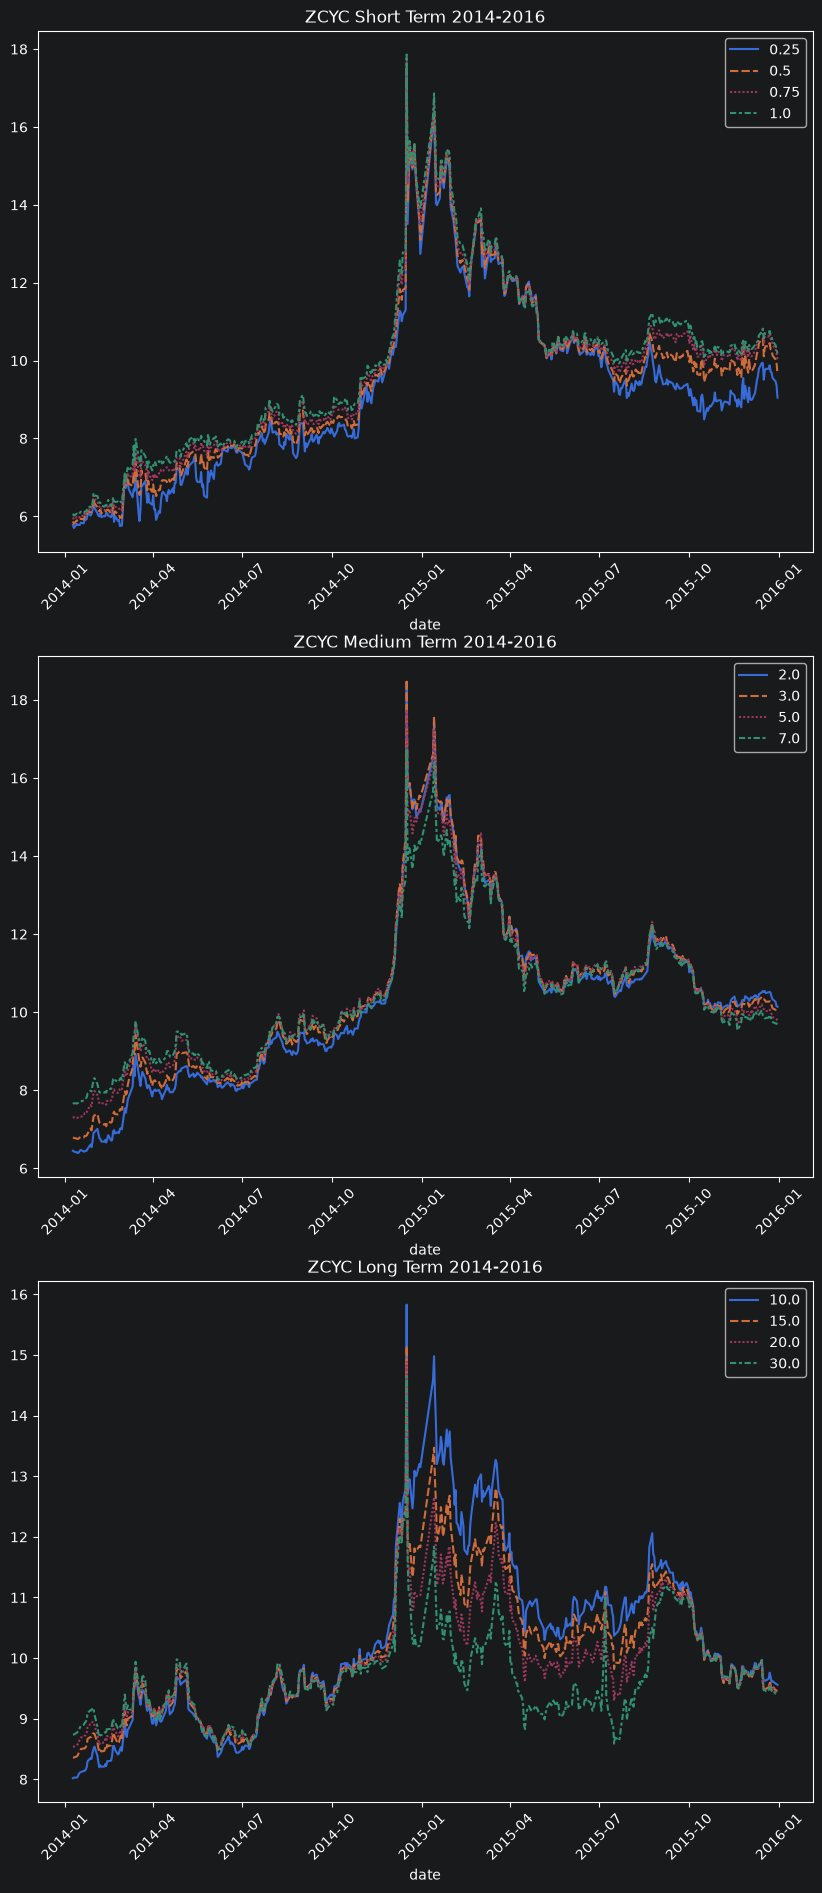

In [13]:
df_2014_2015 = df[
    (df["date"]>="2014-01-01") &
    (df["date"]<"2016-01-01")
]

# Key Rate
plt.figure(figsize=(10, 5))
sns.lineplot(
    df_2014_2015,
    x="date",
    y="key_rate_pct"
)

plt.xticks(rotation=45)
plt.title("Key Rate 2014-2016")
plt.show()


# RUONIA
plt.figure(figsize=(10, 5))
sns.lineplot(
    df_2014_2015,
    x="date",
    y="ruonia_pct"
)

plt.xticks(rotation=45)
plt.title("RUONIA 2014-2016")
plt.show()


# ZCYC
fig, axes = plt.subplots(3, 1, figsize=(10, 23))
(ax1, ax2, ax3) = axes.flatten()

sns.lineplot(
    data=df_2014_2015.set_index("date")[[0.25, 0.5, 0.75, 1.0]],
    ax=ax1
)
ax1.tick_params(axis='x', rotation=45)
ax1.set_title("ZCYC Short Term 2014-2016")


sns.lineplot(
    data=df_2014_2015.set_index("date")[[2, 3, 5, 7]],
    ax=ax2
)
ax2.tick_params(axis='x', rotation=45)
ax2.set_title("ZCYC Medium Term 2014-2016")


sns.lineplot(
    data=df_2014_2015.set_index("date")[[10, 15, 20, 30]],
    ax=ax3
)
ax3.tick_params(axis='x', rotation=45)
ax3.set_title("ZCYC Long Term 2014-2016")


plt.show()

## 2020-2022 period



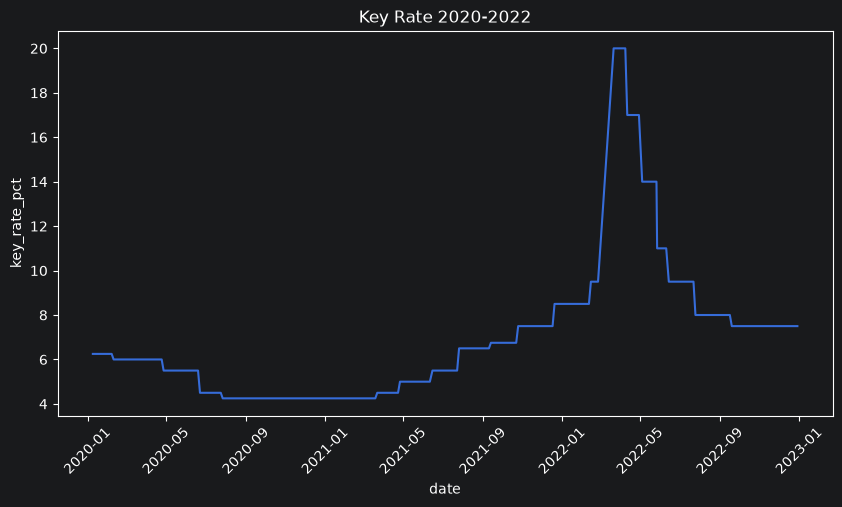

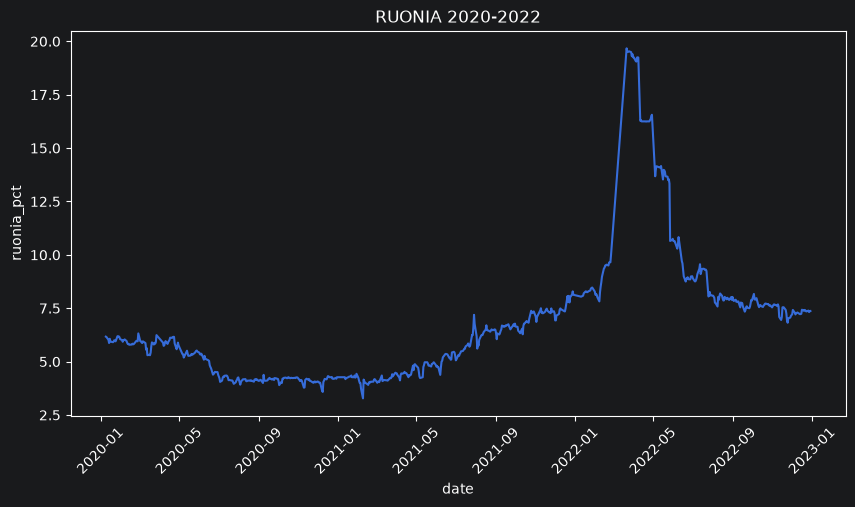

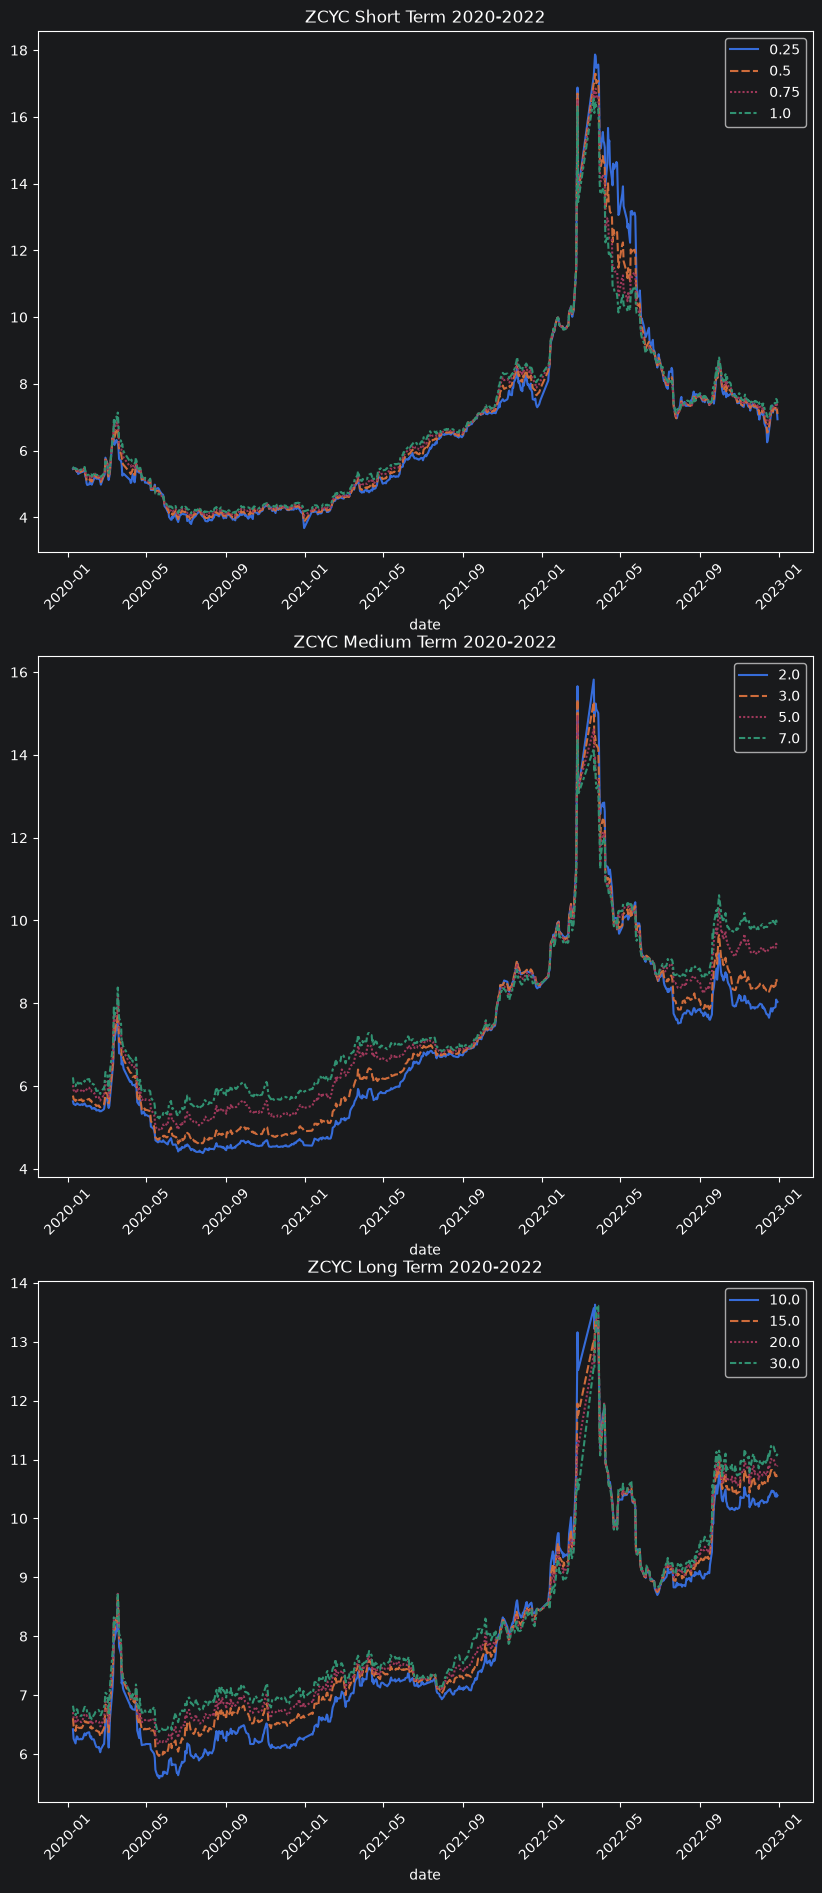

In [14]:
df_2020_2022 = df[
    (df["date"]>="2020-01-01") &
    (df["date"]<"2023-01-01")
]

# Key Rate
plt.figure(figsize=(10, 5))
sns.lineplot(
    df_2020_2022,
    x="date",
    y="key_rate_pct"
)

plt.xticks(rotation=45)
plt.title("Key Rate 2020-2022")
plt.show()


# RUONIA
plt.figure(figsize=(10, 5))
sns.lineplot(
    df_2020_2022,
    x="date",
    y="ruonia_pct"
)

plt.xticks(rotation=45)
plt.title("RUONIA 2020-2022")
plt.show()


# ZCYC
fig, axes = plt.subplots(3, 1, figsize=(10, 23))
(ax1, ax2, ax3) = axes.flatten()

sns.lineplot(
    data=df_2020_2022.set_index("date")[[0.25, 0.5, 0.75, 1.0]],
    ax=ax1
)
ax1.tick_params(axis='x', rotation=45)
ax1.set_title("ZCYC Short Term 2020-2022")


sns.lineplot(
    data=df_2020_2022.set_index("date")[[2, 3, 5, 7]],
    ax=ax2
)
ax2.tick_params(axis='x', rotation=45)
ax2.set_title("ZCYC Medium Term 2020-2022")


sns.lineplot(
    data=df_2020_2022.set_index("date")[[10, 15, 20, 30]],
    ax=ax3
)
ax3.tick_params(axis='x', rotation=45)
ax3.set_title("ZCYC Long Term 2020-2022")


plt.show()

## 2023 - 2026 period

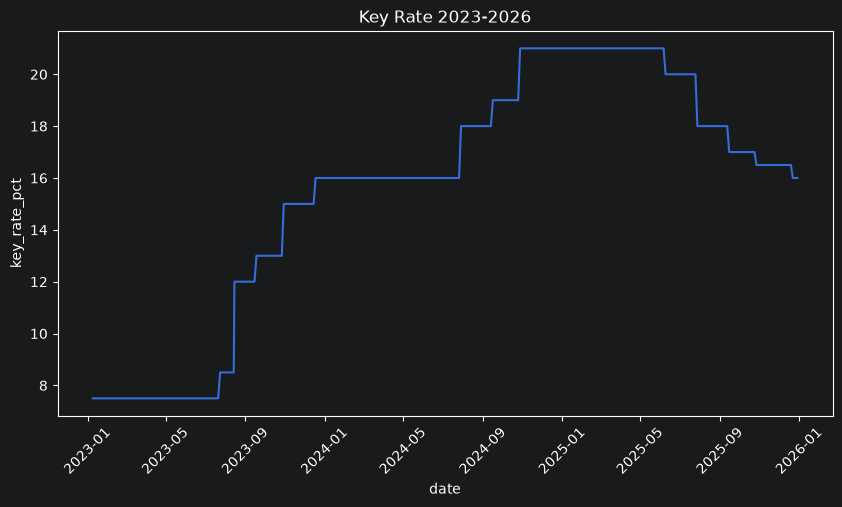

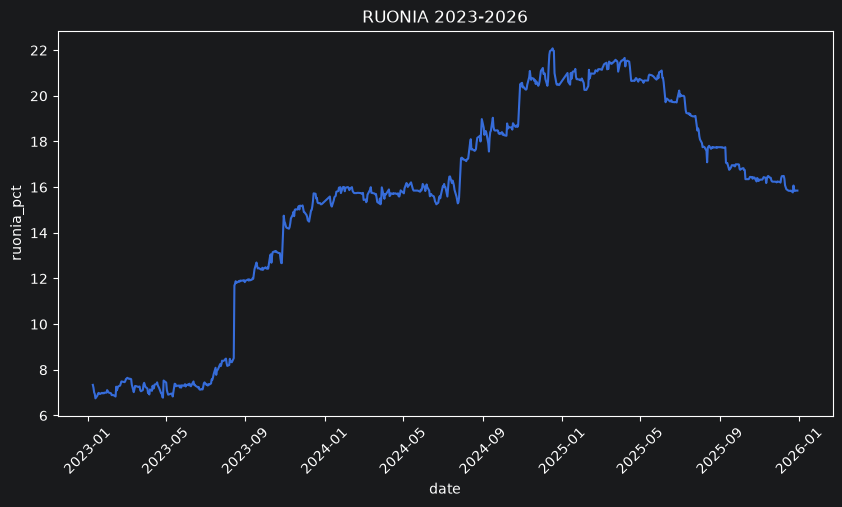

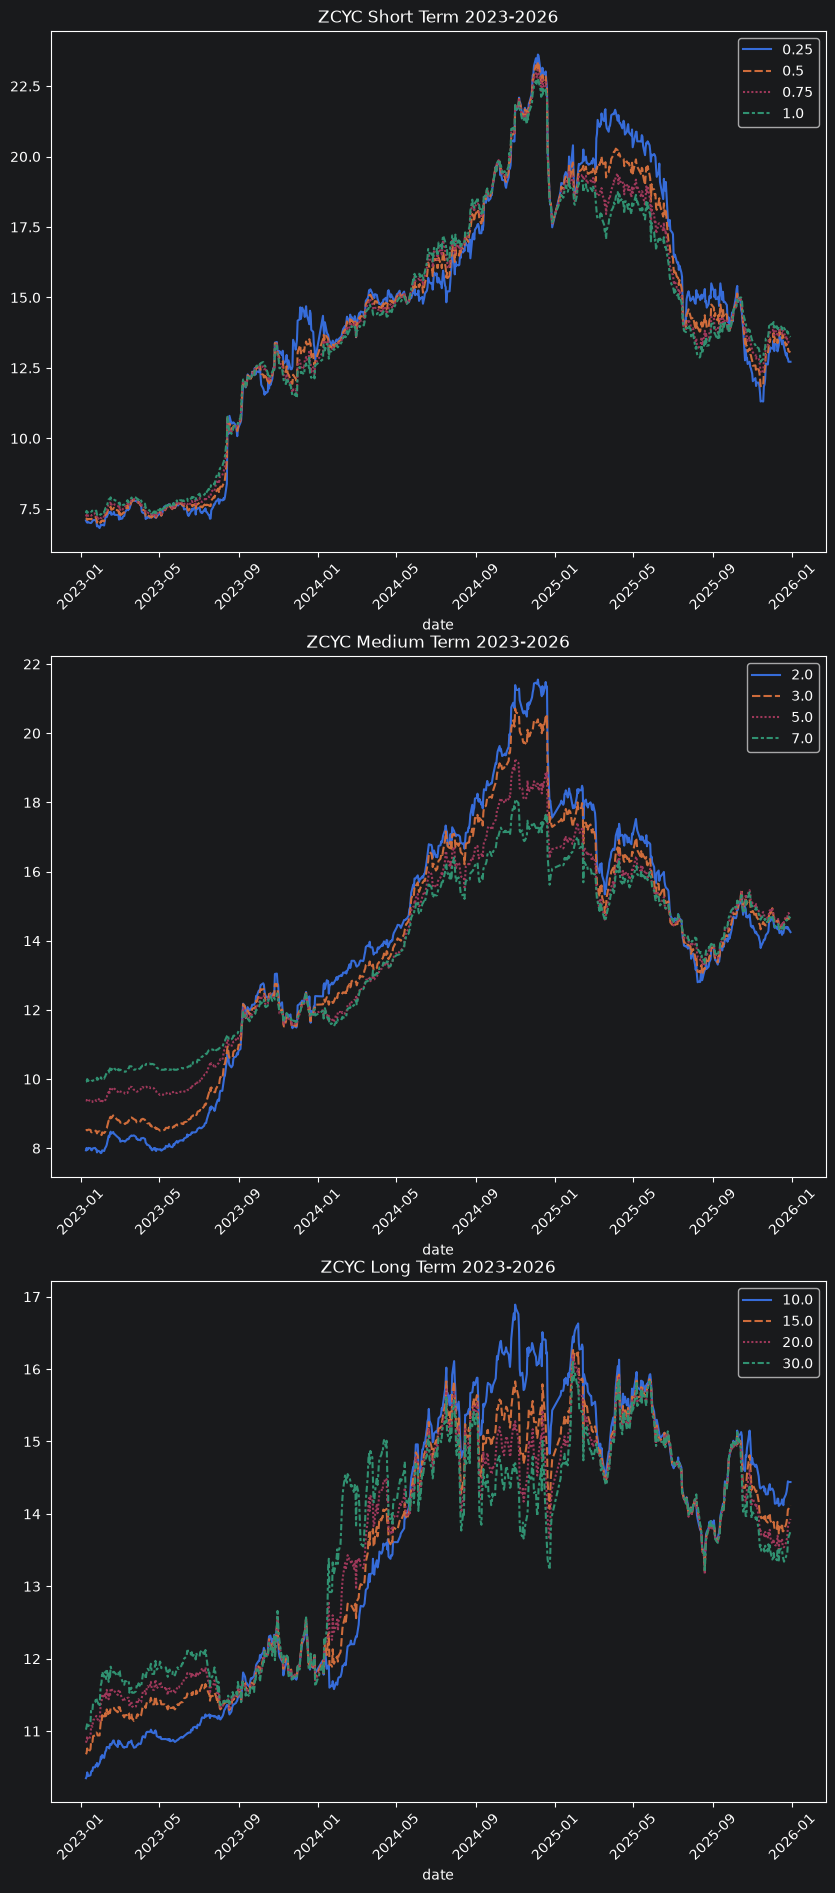

In [15]:
df_2023_2026 = df[
    (df["date"]>="2023-01-01") &
    (df["date"]<"2026-01-01")
]

# Key Rate
plt.figure(figsize=(10, 5))
sns.lineplot(
    df_2023_2026,
    x="date",
    y="key_rate_pct"
)

plt.xticks(rotation=45)
plt.title("Key Rate 2023-2026")
plt.show()


# RUONIA
plt.figure(figsize=(10, 5))
sns.lineplot(
    df_2023_2026,
    x="date",
    y="ruonia_pct"
)

plt.xticks(rotation=45)
plt.title("RUONIA 2023-2026")
plt.show()


# ZCYC
fig, axes = plt.subplots(3, 1, figsize=(10, 23))
(ax1, ax2, ax3) = axes.flatten()

sns.lineplot(
    data=df_2023_2026.set_index("date")[[0.25, 0.5, 0.75, 1.0]],
    ax=ax1
)
ax1.tick_params(axis='x', rotation=45)
ax1.set_title("ZCYC Short Term 2023-2026")


sns.lineplot(
    data=df_2023_2026.set_index("date")[[2, 3, 5, 7]],
    ax=ax2
)
ax2.tick_params(axis='x', rotation=45)
ax2.set_title("ZCYC Medium Term 2023-2026")


sns.lineplot(
    data=df_2023_2026.set_index("date")[[10, 15, 20, 30]],
    ax=ax3
)
ax3.tick_params(axis='x', rotation=45)
ax3.set_title("ZCYC Long Term 2023-2026")


plt.show()